In [1]:
"""
03_nlp_tecnicas.py — Técnicas de Procesamiento de Lenguaje Natural (NLP)
=========================================================================

Este módulo explora técnicas fundamentales de NLP aplicadas al dataset de películas:
1. Preprocesamiento de texto (tokenización, stopwords, stemming, lematización)
2. Representación vectorial (Bag of Words vs TF-IDF)
3. Extracción de características (keywords por género, n-gramas)
4. Nubes de palabras por género (WordClouds)
5. Similitud de documentos (Coseno vs Distancia Euclidiana)
6. Efecto de hiperparámetros en la vectorización
"""

'\n03_nlp_tecnicas.py — Técnicas de Procesamiento de Lenguaje Natural (NLP)\n=========================================================================\n\nEste módulo explora técnicas fundamentales de NLP aplicadas al dataset de películas:\n1. Preprocesamiento de texto (tokenización, stopwords, stemming, lematización)\n2. Representación vectorial (Bag of Words vs TF-IDF)\n3. Extracción de características (keywords por género, n-gramas)\n4. Nubes de palabras por género (WordClouds)\n5. Similitud de documentos (Coseno vs Distancia Euclidiana)\n6. Efecto de hiperparámetros en la vectorización\n'

In [2]:
%matplotlib inline
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from wordcloud import WordCloud
from utils import load_and_clean_data

plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "font.size": 12,
})

OUTPUT_DIR = "output"
def ensure_output_dir():
    import os
    os.makedirs(OUTPUT_DIR, exist_ok=True)
ensure_output_dir()

=============================================================================
PARTE 1: Pipeline de Preprocesamiento de Texto (Tokenización, Stopwords, Stemming, Lematización)
=============================================================================

In [3]:
def demonstrate_preprocessing():
    """
    Demuestra paso a paso las técnicas de preprocesamiento de texto NLP.
    """
    print("\n" + "=" * 70)
    print("PARTE 1: PREPROCESAMIENTO DE TEXTO")
    print("=" * 70)

    text = (
        "Led by Woody, Andy's toys live happily in his room until Andy's "
        "birthday brings Buzz Lightyear onto the scene. Afraid of losing "
        "his place in Andy's heart, Woody plots against Buzz. But when "
        "circumstances separate Buzz and Woody from their owner, the duo "
        "eventually learns to put aside their differences."
    )

    print(f"\n   Texto original ({len(text)} caracteres):")
    print(f"   '{text[:100]}...'")

    text_lower = text.lower()
    print(f"\n   1. Conversión a minúsculas:\n   '{text_lower[:80]}...'")

    text_clean = re.sub(r"[^a-záéíóúüñ\s]", "", text_lower)
    print(f"\n   2. Remoción de puntuación y caracteres especiales:\n   '{text_clean[:80]}...'")

    tokens = word_tokenize(text_clean)
    print(f"\n   3. Tokenización ({len(tokens)} tokens):\n   {tokens[:15]}...")

    stop_en = set(stopwords.words("english"))
    tokens_filtered = [t for t in tokens if t not in stop_en and len(t) > 1]
    print(f"\n   4. Sin stopwords ({len(tokens_filtered)} tokens, removidos {len(tokens) - len(tokens_filtered)}):")
    print(f"   {tokens_filtered[:15]}...")

    porter = PorterStemmer()
    snowball = SnowballStemmer("english")
    stems_porter = [porter.stem(t) for t in tokens_filtered]
    stems_snowball = [snowball.stem(t) for t in tokens_filtered]

    print(f"\n   5. Stemming (Porter vs Snowball):")
    print(f"\n   {'Palabra':<20} {'Porter':<20} {'Snowball':<20}")
    print(f"   {'─' * 20} {'─' * 20} {'─' * 20}")
    for word, p, s in zip(tokens_filtered[:10], stems_porter[:10], stems_snowball[:10]):
        marker = " ←" if word != p else ""
        print(f"   {word:<20} {p:<20} {s:<20}{marker}")

    lemmatizer = WordNetLemmatizer()
    lemmas = [lemmatizer.lemmatize(t) for t in tokens_filtered]

    print(f"\n   6. Lematización (forma base del diccionario):")
    print(f"\n   {'Palabra':<20} {'Stem (Porter)':<20} {'Lema':<20}")
    print(f"   {'─' * 20} {'─' * 20} {'─' * 20}")
    for word, stem, lemma in zip(tokens_filtered[:10], stems_porter[:10], lemmas[:10]):
        print(f"   {word:<20} {stem:<20} {lemma:<20}")

demonstrate_preprocessing()


PARTE 1: PREPROCESAMIENTO DE TEXTO

   Texto original (303 caracteres):
   'Led by Woody, Andy's toys live happily in his room until Andy's birthday brings Buzz Lightyear onto ...'

   1. Conversión a minúsculas:
   'led by woody, andy's toys live happily in his room until andy's birthday brings ...'

   2. Remoción de puntuación y caracteres especiales:
   'led by woody andys toys live happily in his room until andys birthday brings buz...'

   3. Tokenización (50 tokens):
   ['led', 'by', 'woody', 'andys', 'toys', 'live', 'happily', 'in', 'his', 'room', 'until', 'andys', 'birthday', 'brings', 'buzz']...

   4. Sin stopwords (33 tokens, removidos 17):
   ['led', 'woody', 'andys', 'toys', 'live', 'happily', 'room', 'andys', 'birthday', 'brings', 'buzz', 'lightyear', 'onto', 'scene', 'afraid']...

   5. Stemming (Porter vs Snowball):

   Palabra              Porter               Snowball            
   ──────────────────── ──────────────────── ────────────────────
   led               


   6. Lematización (forma base del diccionario):

   Palabra              Stem (Porter)        Lema                
   ──────────────────── ──────────────────── ────────────────────
   led                  led                  led                 
   woody                woodi                woody               
   andys                andi                 andys               
   toys                 toy                  toy                 
   live                 live                 live                
   happily              happili              happily             
   room                 room                 room                
   andys                andi                 andys               
   birthday             birthday             birthday            
   brings               bring                brings              


=============================================================================
PARTE 2: Representación Vectorial de Texto (Bag of Words vs TF-IDF)
=============================================================================

In [4]:
def demonstrate_vectorization():
    """
    Demuestra y compara Bag of Words (CountVectorizer) vs TF-IDF.
    """
    print("\n" + "=" * 70)
    print("PARTE 2: REPRESENTACIÓN VECTORIAL DE TEXTO")
    print("=" * 70)

    corpus = [
        "A toy comes to life in a boy's room",
        "A boy and his toy go on an adventure",
        "A dark knight fights crime in the city",
        "Crime and justice in a dark city",
        "A space adventure with robots and aliens",
    ]
    labels = ["Toy Story (sim.)", "Toy Adventure", "Dark Knight (sim.)", "Crime City", "Space Adventure"]

    count_vec = CountVectorizer(stop_words="english")
    bow_matrix = count_vec.fit_transform(corpus)
    vocab = count_vec.get_feature_names_out()

    print(f"\n   Matriz BoW (CountVectorizer):")
    bow_df = pd.DataFrame(bow_matrix.toarray(), columns=vocab, index=labels)
    print(f"   {bow_df.to_string()}")

    tfidf_vec = TfidfVectorizer(stop_words="english")
    tfidf_matrix = tfidf_vec.fit_transform(corpus)

    print(f"\n   Matriz TF-IDF (valores ponderados):")
    tfidf_df = pd.DataFrame(tfidf_matrix.toarray().round(3), columns=tfidf_vec.get_feature_names_out(), index=labels)
    print(f"   {tfidf_df.to_string()}")

    cos_bow = cosine_similarity(bow_matrix)
    cos_tfidf = cosine_similarity(tfidf_matrix)

    print(f"\n   Similitud Coseno (Bag of Words):")
    print(f"   {pd.DataFrame(cos_bow.round(3), columns=labels, index=labels).to_string()}")

    print(f"\n   Similitud Coseno (TF-IDF):")
    print(f"   {pd.DataFrame(cos_tfidf.round(3), columns=labels, index=labels).to_string()}")
    return bow_matrix, tfidf_matrix, count_vec, tfidf_vec, labels

bow_matrix, tfidf_matrix, count_vec, tfidf_vec, labels = demonstrate_vectorization()


PARTE 2: REPRESENTACIÓN VECTORIAL DE TEXTO

   Matriz BoW (CountVectorizer):
                       adventure  aliens  boy  city  comes  crime  dark  fights  justice  knight  life  robots  room  space  toy
Toy Story (sim.)            0       0    1     0      1      0     0       0        0       0     1       0     1      0    1
Toy Adventure               1       0    1     0      0      0     0       0        0       0     0       0     0      0    1
Dark Knight (sim.)          0       0    0     1      0      1     1       1        0       1     0       0     0      0    0
Crime City                  0       0    0     1      0      1     1       0        1       0     0       0     0      0    0
Space Adventure             1       1    0     0      0      0     0       0        0       0     0       1     0      1    0

   Matriz TF-IDF (valores ponderados):
                       adventure  aliens    boy   city  comes  crime   dark  fights  justice  knight   life  robots   room 

=============================================================================
PARTE 3: Extracción de Características y Nubes de Palabras (WordClouds)
=============================================================================

Cargando movies_metadata.csv...


Parseando columnas JSON (genres, production_companies)...


Mergeando con keywords.csv...


Dataset listo: 45433 películas cargadas

PARTE 3: EXTRACCIÓN DE CARACTERÍSTICAS Y WORDCLOUDS

   Action (6592 películas):
      martial arts               289 ████████████████████
      revenge                    238 ████████████████
      murder                     210 ██████████████
      violence                   207 ██████████████
      independent film           176 ████████████
      sequel                     161 ███████████
      police                     160 ███████████
      superhero                  147 ██████████
      dystopia                   139 █████████
      based on comic             111 ███████

   Comedy (13176 películas):
      woman director             795 ████████████████████
      independent film           741 ██████████████████
      musical                    376 █████████
      stand-up comedy            344 ████████
      duringcreditsstinger       266 ██████
      sex                        254 ██████
      love                       216 █████
      


   Top 10 Unigramas:
      life                            7872 █████████████████████████
      young                           6493 ████████████████████
      film                            5974 ██████████████████
      man                             5723 ██████████████████
      new                             5665 █████████████████
      love                            5192 ████████████████
      family                          4799 ███████████████
      world                           4794 ███████████████
      story                           4582 ██████████████
      old                             3910 ████████████



   Top 10 Bigramas:
      year old                        1717 █████████████████████████
      new york                        1357 ███████████████████
      high school                      860 ████████████
      falls love                       822 ███████████
      young woman                      753 ██████████
      young man                        734 ██████████
      world war                        658 █████████
      small town                       614 ████████
      best friend                      507 ███████
      tells story                      477 ██████



   Top 10 Trigramas:
      new york city                    410 █████████████████████████
      world war ii                     397 ████████████████████████
      based true story                 153 █████████
      year old boy                     127 ███████
      year old girl                    118 ███████
      12 year old                      113 ██████
      year old son                     108 ██████
      year old daughter                 95 █████
      17 year old                       88 █████
      film tells story                  85 █████


C:\Users\PC 1\AppData\Local\Temp\ipykernel_22584\4063463677.py:62: UserWarning: Glyph 9729 (\N{CLOUD}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\PC 1\AppData\Local\Temp\ipykernel_22584\4063463677.py:62: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\PC 1\AppData\Local\Temp\ipykernel_22584\4063463677.py:64: UserWarning: Glyph 9729 (\N{CLOUD}) missing from font(s) Arial.
  plt.savefig(path, dpi=150, bbox_inches="tight")
C:\Users\PC 1\AppData\Local\Temp\ipykernel_22584\4063463677.py:64: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  plt.savefig(path, dpi=150, bbox_inches="tight")


C:\Users\PC 1\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9729 (\N{CLOUD}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\PC 1\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


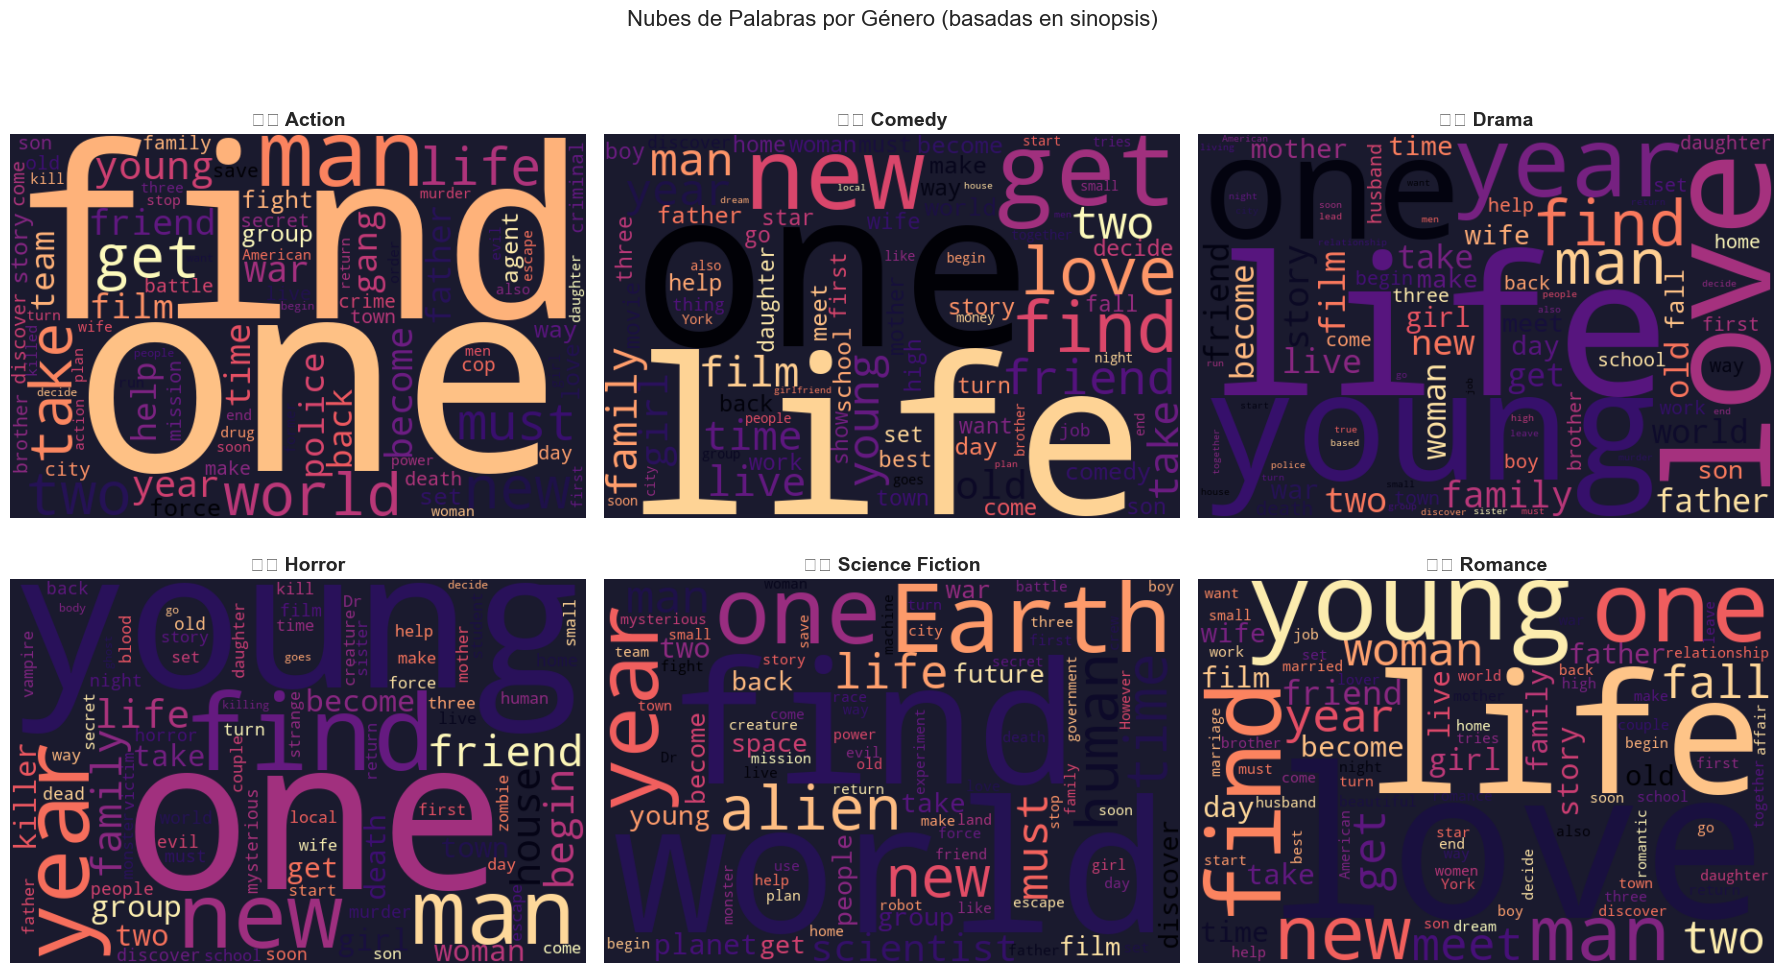

   Guardado: output/03_wordclouds_por_genero.png


In [5]:
df = load_and_clean_data(include_keywords=True)

def extract_features(df):
    """
    Extrae y visualiza características del dataset de películas:
    - Keywords más frecuentes por género
    - N-gramas más comunes en overviews
    - Nubes de palabras por género
    """
    ensure_output_dir()
    print("\n" + "=" * 70)
    print("PARTE 3: EXTRACCIÓN DE CARACTERÍSTICAS Y WORDCLOUDS")
    print("=" * 70)

    genres_to_analyze = ["Action", "Comedy", "Drama", "Horror", "Science Fiction"]
    for genre in genres_to_analyze:
        genre_movies = df[df["genres_list"].apply(lambda x: genre in x)]
        all_keywords = genre_movies["keywords_list"].explode()
        top_keywords = all_keywords.value_counts().head(10)
        print(f"\n   {genre} ({len(genre_movies)} películas):")
        for kw, count in top_keywords.items():
            bar = "█" * min(int(count / top_keywords.max() * 20), 20)
            print(f"      {kw:<25} {count:4d} {bar}")

    overviews = df[df["overview"] != ""]["overview"]
    for n, label in [(1, "Unigramas"), (2, "Bigramas"), (3, "Trigramas")]:
        vec = CountVectorizer(stop_words="english", ngram_range=(n, n), max_features=10)
        matrix = vec.fit_transform(overviews)
        freqs = zip(vec.get_feature_names_out(), matrix.sum(axis=0).A1)
        sorted_freqs = sorted(freqs, key=lambda x: x[1], reverse=True)
        print(f"\n   Top 10 {label}:")
        for term, freq in sorted_freqs:
            bar = "█" * min(int(freq / sorted_freqs[0][1] * 25), 25)
            print(f"      {term:<30} {int(freq):5d} {bar}")

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    genres_for_cloud = ["Action", "Comedy", "Drama", "Horror", "Science Fiction", "Romance"]

    for ax, genre in zip(axes.flatten(), genres_for_cloud):
        genre_movies = df[df["genres_list"].apply(lambda x: genre in x)]
        text = " ".join(genre_movies["overview"].dropna())
        if not text.strip():
            ax.set_title(f"{genre} (sin datos)")
            ax.axis("off")
            continue

        wc = WordCloud(
            width=600,
            height=400,
            background_color="#1a1a2e",
            colormap="magma",
            max_words=80,
            stopwords=set(stopwords.words("english")),
            collocations=False,
        ).generate(text)

        ax.imshow(wc, interpolation="bilinear")
        ax.set_title(f"{genre}", fontsize=14, fontweight="bold")
        ax.axis("off")

    plt.suptitle("Nubes de Palabras por Género (basadas en sinopsis)", fontsize=16, y=1.02)
    plt.tight_layout()
    path = f"{OUTPUT_DIR}/03_wordclouds_por_genero.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"   Guardado: {path}")

extract_features(df)

=============================================================================
PARTE 4: Similitud de Documentos (Coseno vs Distancia Euclidiana)
=============================================================================


PARTE 4: SIMILITUD DE DOCUMENTOS (COSENO vs EUCLIDIANA)
   Película de referencia: 'Toy Story'
   Sinopsis: 'Led by Woody, Andy's toys live happily in his room until Andy's birthday brings Buzz Lightyear onto the scene. Afraid of...'

   Top 5 más similares (Similitud Coseno):
   1. Condorman                           Coseno: 0.1905 │ Euclidiana: 1.2724
   2. Rebel Without a Cause               Coseno: 0.1798 │ Euclidiana: 1.2808
   3. The Sunchaser                       Coseno: 0.1691 │ Euclidiana: 1.2891
   4. Malice                              Coseno: 0.1640 │ Euclidiana: 1.2931
   5. For Love or Money                   Coseno: 0.1426 │ Euclidiana: 1.3095

   Top 5 más similares (Distancia Euclidiana):
   1. Condorman                           Coseno: 0.1905 │ Euclidiana: 1.2724
   2. Rebel Without a Cause               Coseno: 0.1798 │ Euclidiana: 1.2808
   3. The Sunchaser                       Coseno: 0.1691 │ Euclidiana: 1.2891
   4. Malice                              Coseno:

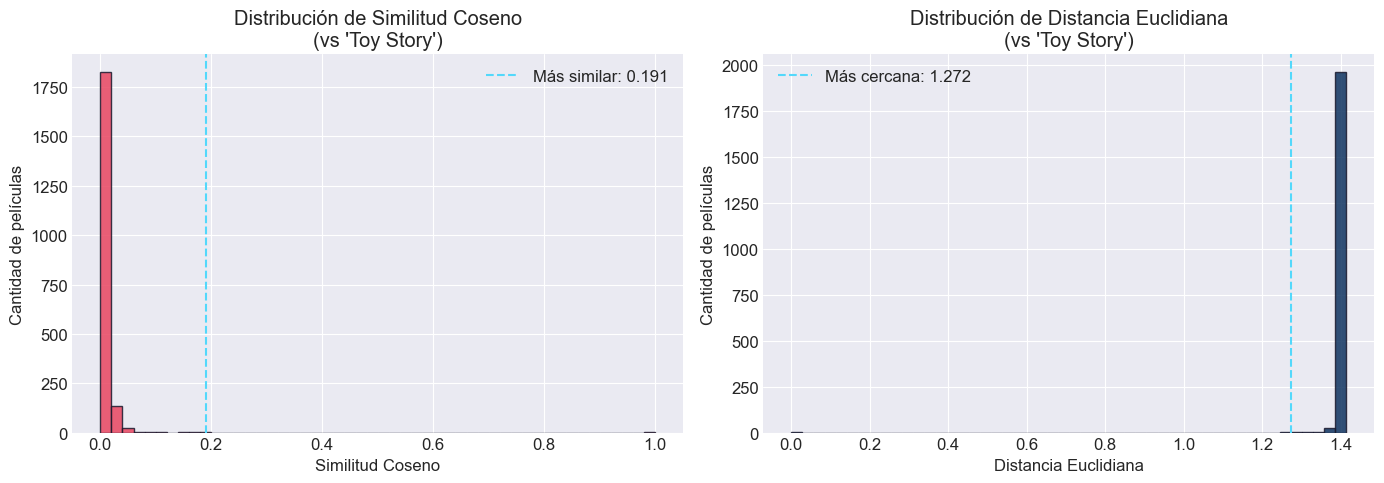


   Guardado: output/03_coseno_vs_euclidiana.png


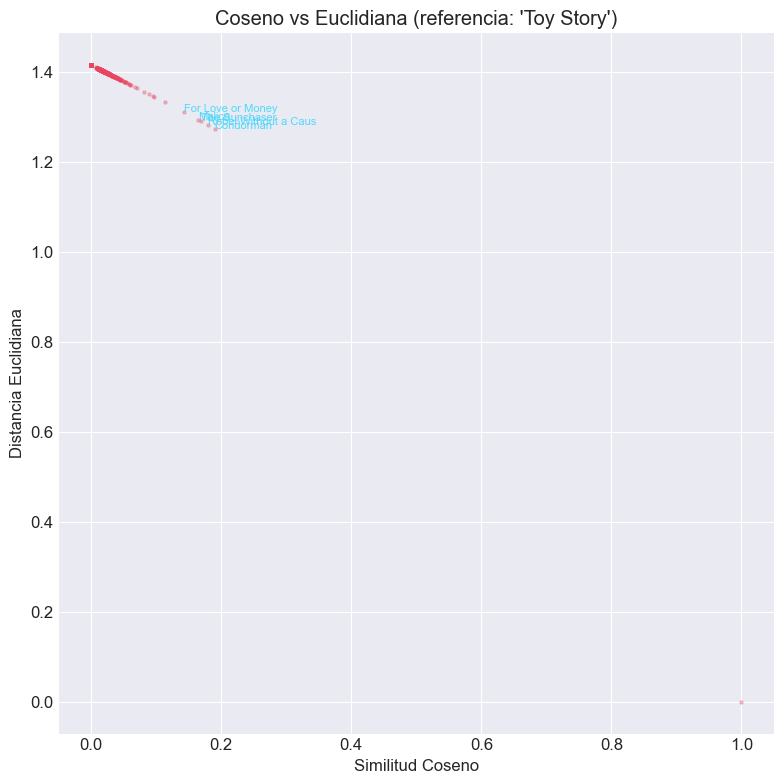

   Guardado: output/03_coseno_vs_euclidiana_scatter.png


In [6]:
def demonstrate_document_similarity(df, n_sample=2000):
    """
    Demuestra la similitud de documentos sobre sinopsis reales.
    Compara similitud coseno vs distancia euclidiana.
    """
    ensure_output_dir()
    print("\n" + "=" * 70)
    print("PARTE 4: SIMILITUD DE DOCUMENTOS (COSENO vs EUCLIDIANA)")
    print("=" * 70)

    sample = df[df["overview"] != ""].head(n_sample).copy().reset_index(drop=True)
    tfidf = TfidfVectorizer(stop_words="english", max_features=5000)
    tfidf_matrix = tfidf.fit_transform(sample["overview"])

    ref_title = "Toy Story"
    ref_matches = sample[sample["title"] == ref_title]
    ref_idx = ref_matches.index[0] if not ref_matches.empty else 0
    ref_title = sample.iloc[ref_idx]["title"]

    print(f"   Película de referencia: '{ref_title}'")
    print(f"   Sinopsis: '{sample.iloc[ref_idx]['overview'][:120]}...'")

    cos_sims = cosine_similarity(tfidf_matrix[ref_idx:ref_idx + 1], tfidf_matrix).flatten()
    euc_dists = euclidean_distances(tfidf_matrix[ref_idx:ref_idx + 1], tfidf_matrix).flatten()

    top_cos_idx = cos_sims.argsort()[::-1][1:6]
    print(f"\n   Top 5 más similares (Similitud Coseno):")
    for rank, idx in enumerate(top_cos_idx, 1):
        print(f"   {rank}. {sample.iloc[idx]['title']:<35} Coseno: {cos_sims[idx]:.4f} │ Euclidiana: {euc_dists[idx]:.4f}")

    top_euc_idx = euc_dists.argsort()[1:6]
    print(f"\n   Top 5 más similares (Distancia Euclidiana):")
    for rank, idx in enumerate(top_euc_idx, 1):
        print(f"   {rank}. {sample.iloc[idx]['title']:<35} Coseno: {cos_sims[idx]:.4f} │ Euclidiana: {euc_dists[idx]:.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hist(cos_sims, bins=50, color="#e94560", edgecolor="#1a1a2e", alpha=0.85)
    axes[0].set_title(f"Distribución de Similitud Coseno\n(vs '{ref_title}')")
    axes[0].set_xlabel("Similitud Coseno")
    axes[0].set_ylabel("Cantidad de películas")
    axes[0].axvline(cos_sims[top_cos_idx[0]], color="#53d8fb", linestyle="--",
                    label=f"Más similar: {cos_sims[top_cos_idx[0]]:.3f}")
    axes[0].legend()

    axes[1].hist(euc_dists, bins=50, color="#0f3460", edgecolor="#1a1a2e", alpha=0.85)
    axes[1].set_title(f"Distribución de Distancia Euclidiana\n(vs '{ref_title}')")
    axes[1].set_xlabel("Distancia Euclidiana")
    axes[1].set_ylabel("Cantidad de películas")
    axes[1].axvline(euc_dists[top_euc_idx[0]], color="#53d8fb", linestyle="--",
                    label=f"Más cercana: {euc_dists[top_euc_idx[0]]:.3f}")
    axes[1].legend()

    plt.tight_layout()
    path_dist = f"{OUTPUT_DIR}/03_coseno_vs_euclidiana.png"
    plt.savefig(path_dist, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\n   Guardado: {path_dist}")

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.scatter(cos_sims, euc_dists, alpha=0.3, s=5, color="#e94560")
    ax.set_xlabel("Similitud Coseno")
    ax.set_ylabel("Distancia Euclidiana")
    ax.set_title(f"Coseno vs Euclidiana (referencia: '{ref_title}')")

    for idx in top_cos_idx:
        ax.annotate(sample.iloc[idx]["title"][:20],
                    (cos_sims[idx], euc_dists[idx]),
                    fontsize=8, color="#53d8fb")

    plt.tight_layout()
    path_scatter = f"{OUTPUT_DIR}/03_coseno_vs_euclidiana_scatter.png"
    plt.savefig(path_scatter, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"   Guardado: {path_scatter}")

demonstrate_document_similarity(df, n_sample=2000)

=============================================================================
PARTE 5: Efecto de Parámetros en la Vectorización
=============================================================================

In [7]:
def demonstrate_parameter_effects(df):
    """
    Muestra cómo diferentes parámetros del vectorizador
    afectan el vocabulario y las recomendaciones.
    """
    print("\n" + "=" * 70)
    print("PARTE 5: EFECTO DE PARÁMETROS EN LA VECTORIZACIÓN")
    print("=" * 70)

    overviews = df[df["overview"] != ""]["overview"]
    configs = [
        {"name": "Default", "params": {"stop_words": "english"}},
        {"name": "Bigramas", "params": {"stop_words": "english", "ngram_range": (1, 2)}},
        {"name": "Max 1000 feat.", "params": {"stop_words": "english", "max_features": 1000}},
        {"name": "Min DF=5", "params": {"stop_words": "english", "min_df": 5}},
        {"name": "Max DF=0.5", "params": {"stop_words": "english", "max_df": 0.5}},
        {"name": "Sublinear TF", "params": {"stop_words": "english", "sublinear_tf": True}},
    ]

    print(f"\n   {'Configuración':<20} {'Vocabulario':>12} {'Sparsidad':>12} {'NNZ':>12}")
    print(f"   {'─' * 20} {'─' * 12} {'─' * 12} {'─' * 12}")

    for config in configs:
        tfidf = TfidfVectorizer(**config["params"])
        matrix = tfidf.fit_transform(overviews)
        vocab_size = len(tfidf.vocabulary_)
        sparsity = 1.0 - (matrix.nnz / (matrix.shape[0] * matrix.shape[1]))
        nnz = matrix.nnz
        print(f"   {config['name']:<20} {vocab_size:>12,} {sparsity:>11.4%} {nnz:>12,}")

demonstrate_parameter_effects(df)


PARTE 5: EFECTO DE PARÁMETROS EN LA VECTORIZACIÓN

   Configuración         Vocabulario    Sparsidad          NNZ
   ──────────────────── ──────────── ──────────── ────────────


   Default                    75,827    99.9641%    1,209,964


   Bigramas                1,046,384    99.9947%    2,474,966


   Max 1000 feat.              1,000    98.7334%      563,390


   Min DF=5                   20,740    99.8778%    1,127,071


   Max DF=0.5                 75,827    99.9641%    1,209,964


   Sublinear TF               75,827    99.9641%    1,209,964


In [8]:
print("\n" + "=" * 70)
print("Módulo 03 completado exitosamente. Visualizaciones generadas en output/")
print("=" * 70)


Módulo 03 completado exitosamente. Visualizaciones generadas en output/
